# Exercice 2 : Réseau de neurones sur Iris

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

tf.keras.utils.set_random_seed(42)

In [2]:
# Etape 2 - Charger le dataset Iris

iris = load_iris()
X = iris.data
y = iris.target

print("Dimensions X: ", X.shape)
print("Dimensions y: ", y.shape)

Dimensions X:  (150, 4)
Dimensions y:  (150,)


In [3]:
# Etape 3 - Visualiser les 5 premières lignes

print("Exemple de X : \n", X[:5])
print("Exemple de y : \n", y[:5])

Exemple de X : 
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Exemple de y : 
 [0 0 0 0 0]


In [4]:
# Etape 4 - Split train/test

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Taille train : ", X_train.shape)
print("Taille test : ", X_test.shape)

Taille train :  (120, 4)
Taille test :  (30, 4)


In [5]:
# Etape 5 : One-Hot Encoding pour les sorties

encoder = OneHotEncoder(sparse_output=False)
y_train = encoder.fit_transform(y_train.reshape(-1,1))
y_test = encoder.transform(y_test.reshape(-1,1))
print("Sorties encodées :\n", y_train[:5])

Sorties encodées :
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


In [6]:
# Etape 6 : Normaliser les features (standardisation)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Features normalisées :\n", X_train[:5])

Features normalisées :
 [[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [7]:
# Etape 7 : Construire le modèle MLP

model = Sequential([
    Input(shape=(4,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

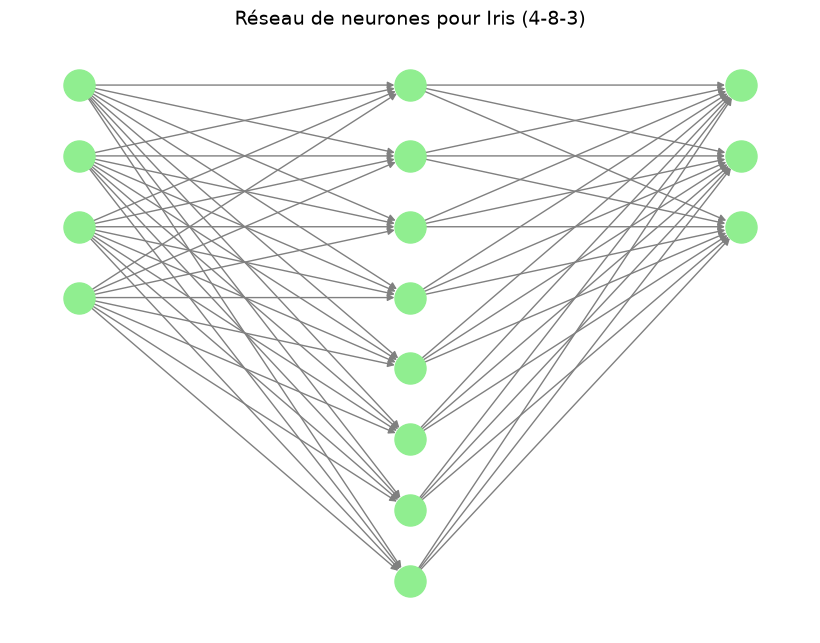

In [9]:
layers = [4, 8, 3]

G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layers):
    layer_pos = []
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, -i) # Positionnner les neurones en colonnes
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)

for l in range(len(layers) - 1):
    for src in layer_positions[l]:
        for dst in layer_positions[l + 1]:
            G.add_edge(src, dst)

plt.figure(figsize=(8 ,6))
nx.draw(G, pos, with_labels=False, node_size=500, node_color="lightgreen", edge_color="gray")
plt.title("Réseau de neurones pour Iris (4-8-3)", fontsize=14)
plt.show()

In [10]:
# 8 : Compiler le modele

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
# Etape 9 : Entrainer le modele
# X_train : Données d'entrée d'apprentissage
# y_train : Etiquettes d'apprentissage (labels des colonnes en gros)
# epochs (int) : Nombre d'itérations sur l'ensemble, une epoch signifie que le modele a vu chaque exemple du jeu d'entrainement une fois
# batch_size (int): Nombre d'exemples utilisés dans une seule itération avant la mise a jour des poids du modele
# validation_split (float entre 0 et 1) : Fraction des données d'apprentissage servant a la validation; ici 90% des données sont pour l'entrainement et 10% pour la validation


history = model.fit(X_train, y_train, epochs=100, batch_size=5, validation_split=0.1)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6389 - loss: 0.8449 - val_accuracy: 0.6667 - val_loss: 0.8814
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7222 - loss: 0.7955 - val_accuracy: 0.6667 - val_loss: 0.8358
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7037 - loss: 0.7498 - val_accuracy: 0.6667 - val_loss: 0.7926
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7222 - loss: 0.7077 - val_accuracy: 0.6667 - val_loss: 0.7534
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7407 - loss: 0.6687 - val_accuracy: 0.6667 - val_loss: 0.7191
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7685 - loss: 0.6339 - val_accuracy: 0.6667 - val_loss: 0.6890
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7778 - loss: 0.6033 - val_accuracy: 0.6667 - val_loss: 0.6631
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7778 - loss: 0.5764 - val_accuracy: 0.6667 - 

In [12]:
# Etape 10 : Evaluer le modele sur le test set

loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy : {accuracy*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9333 - loss: 0.1620
Test accuracy : 93.33%


In [15]:
# Etape 11 : Visualiser la prédiction pour quelque exemples

predictions = model.predict(X_test)
print("Prédictions :\n", predictions[:5].round(3))
print("Classes prédites : ", np.argmax(predictions, axis=1)[:20])
print(f"Vraies classes   : ", np.argmax(y_test, axis=1)[:20])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Prédictions :
 [[0.998 0.002 0.   ]
 [0.001 0.206 0.793]
 [0.043 0.948 0.009]
 [0.016 0.978 0.007]
 [0.999 0.001 0.   ]]
Classes prédites :  [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]
Vraies classes   :  [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]


In [17]:
y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(predictions, axis=1)

df = pd.DataFrame(scaler.inverse_transform(X_test), columns=iris.feature_names).round(1)

df['True Class'] = y_true
df['Predicted Class'] = y_pred

df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True Class,Predicted Class
0,4.4,3.0,1.3,0.2,0,0
1,6.1,3.0,4.9,1.8,2,2
2,4.9,2.4,3.3,1.0,1,1
3,5.0,2.3,3.3,1.0,1,1
4,4.4,3.2,1.3,0.2,0,0
5,6.3,3.3,4.7,1.6,1,1
6,4.6,3.6,1.0,0.2,0,0
7,5.4,3.4,1.7,0.2,0,0
8,6.5,3.0,5.2,2.0,2,2
9,5.4,3.0,4.5,1.5,1,1
